<a href="https://colab.research.google.com/github/luanoliveira-pixel/pcd-aulasiniciais/blob/main/PCD_Projeto_Pr%C3%A1tico_Individual_IPCA_e_Selic.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# A Selic acompanha a inflação no Brasil?

**Disciplina:** Programação para Ciência de Dados
**Aluno:** Luan Gabriel Bach de Oliveira

## 1. Definição do problema

**Tema:** inflação e juros no Brasil. O Banco Central usa a taxa Selic para tentar controlar a inflação (IPCA).

**Pergunta:** quando a inflação sobe, a Selic sobe junto? Em quais anos a Selic rendeu menos que a inflação?

**Informações que pretendo obter a partir dos dados.**
1. IPCA e Selic acumulados em cada ano.
2. O **juro real** de cada ano (quanto a Selic rendeu acima da inflação).
3. Os anos em que o juro real foi negativo.
4. Se IPCA e Selic andam juntos (correlação).

**Fonte dos dados:** arquivo ipca_selic_mensal.csv, com duas séries do Sistema Gerenciador de Séries Temporais (SGS) do Banco Central:
- série 433: IPCA, variação mensal (% ao mês)
- série 4390: Selic acumulada no mês (% ao mês)


Endereço da fonte: https://www3.bcb.gov.br/sgspub/localizarseries/localizarSeries.do?method=prepararTelaLocalizarSeries

## 2. Obtenção e exploração dos dados

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# Carregar o CSV (a data vira o índice da tabela)
df = pd.read_csv("ipca_selic_mensal.csv", index_col="data", parse_dates=True)
df.columns = ["ipca", "selic"]  # nomes mais curtos

# Explorar
print(df.head())
print("\nRegistros e atributos:", df.shape)
print("\nTipos de dados:")
print(df.dtypes)
print("\nValores ausentes:")
print(df.isna().sum())
print("\nDatas repetidas:", df.index.duplicated().sum())
df.describe()

            ipca  selic
data                   
2010-01-01  0.75   0.66
2010-02-01  0.78   0.59
2010-03-01  0.52   0.76
2010-04-01  0.57   0.67
2010-05-01  0.43   0.75

Registros e atributos: (200, 2)

Tipos de dados:
ipca     float64
selic    float64
dtype: object

Valores ausentes:
ipca     1
selic    0
dtype: int64

Datas repetidas: 0


,ipca,selic
count,199.000000,200.000000
mean,0.469698,0.790600
std,0.357241,0.282943
min,-0.680000,0.130000
25%,0.240000,0.570000
50%,0.440000,0.835000
75%,0.680000,1.020000
max,1.620000,1.280000


**O que observei:** cada linha é um mês, com duas colunas numéricas. As datas foram convertidas para data (parse_dates) e os valores são números. O último mês está sem IPCA, porque o IBGE divulga o índice depois da Selic.

## 3. Preparação dos dados

**Decisões**
- Apaguei os meses sem IPCA (dropna). Seu eu preenchesse com algum número, inventaria números de inflação e estragaria a análise.
- Criei a coluna ano para poder agrupar.
- Criei o **juro real** mensal: (1 + selic) / (1 + ipca) - 1. Essa conta é melhor do que selic - ipca.

In [ ]:
df = df.dropna()
df["ano"] = df.index.year
df["juro_real"] = ((1 + df["selic"] / 100) / (1 + df["ipca"] / 100) - 1) * 100
df.tail()

,ipca,selic,ano,juro_real
data,,,,
2026-03-01,0.88,1.21,2026,0.327121
2026-04-01,0.67,1.09,2026,0.417205
2026-05-01,0.58,1.07,2026,0.487174
2026-06-01,0.16,1.12,2026,0.958466
2026-07-01,0.07,1.22,2026,1.149196


## 4. Análise dos dados

### 4.1 Função e laço: taxa acumulada por ano
Os percentuais mensais se acumulam multiplicando (juros compostos), e não somando.

In [ ]:
def acumular(taxas):
    """Recebe taxas mensais em % e devolve a taxa acumulada em %."""
    total = 1
    for taxa in taxas:                 # laço: multiplica mês a mês
        total = total * (1 + taxa / 100)
    return (total - 1) * 100


def classificar(juro_real):
    """Teste condicional: diz se o juro real do ano foi bom ou ruim para quem investiu."""
    if juro_real < 0:
        return "perdeu da inflação"
    elif juro_real < 5:
        return "ganho moderado"
    else:
        return "ganho alto"


linhas = []
for ano in sorted(df["ano"].unique()):            # laço: um ano de cada vez
    parte = df[df["ano"] == ano]                  # filtro com pandas
    ipca = acumular(parte["ipca"])
    selic = acumular(parte["selic"])
    juro_real = ((1 + selic / 100) / (1 + ipca / 100) - 1) * 100
    linhas.append({"ano": ano, "meses": len(parte), "ipca": ipca, "selic": selic,
                   "juro_real": juro_real, "situacao": classificar(juro_real)})

anual = pd.DataFrame(linhas).set_index("ano")
anual.round(2)

,meses,ipca,selic,juro_real,situacao
ano,,,,,
2010,12,5.91,9.78,3.66,ganho moderado
2011,12,6.50,11.62,4.80,ganho moderado
2012,12,5.84,8.48,2.50,ganho moderado
2013,12,5.91,8.21,2.17,ganho moderado
2014,12,6.41,10.91,4.23,ganho moderado
2015,12,10.67,13.29,2.36,ganho moderado
2016,12,6.29,14.03,7.28,ganho alto
2017,12,2.95,9.96,6.81,ganho alto
2018,12,3.75,6.42,2.58,ganho moderado


### 4.2 Orientação a objetos
Uma classe que guarda a tabela anual e responde às perguntas do problema. Anos com menos de 12 meses (o ano atual) ficam de fora dos rankings, porque ainda estão incompletos.

In [ ]:
class AnaliseAnual:
    def __init__(self, tabela):
        self.tabela = tabela[tabela["meses"] == 12]   # só anos completos

    def anos_juro_negativo(self):
        return list(self.tabela[self.tabela["juro_real"] < 0].index)

    def melhor_ano(self):
        return self.tabela["juro_real"].idxmax()

    def pior_ano(self):
        return self.tabela["juro_real"].idxmin()

    def correlacao(self):
        return self.tabela["ipca"].corr(self.tabela["selic"])


analise = AnaliseAnual(anual)
print("Anos em que a Selic perdeu da inflação:", analise.anos_juro_negativo())
print("Melhor ano para o juro real:", analise.melhor_ano())
print("Pior ano para o juro real:", analise.pior_ano())
print("Correlação entre IPCA e Selic (anos completos):", round(analise.correlacao(), 2))

Anos em que a Selic perdeu da inflação: [2020, 2021]
Melhor ano para o juro real: 2025
Pior ano para o juro real: 2021
Correlação entre IPCA e Selic (anos completos): 0.07


### 4.3 Gráficos

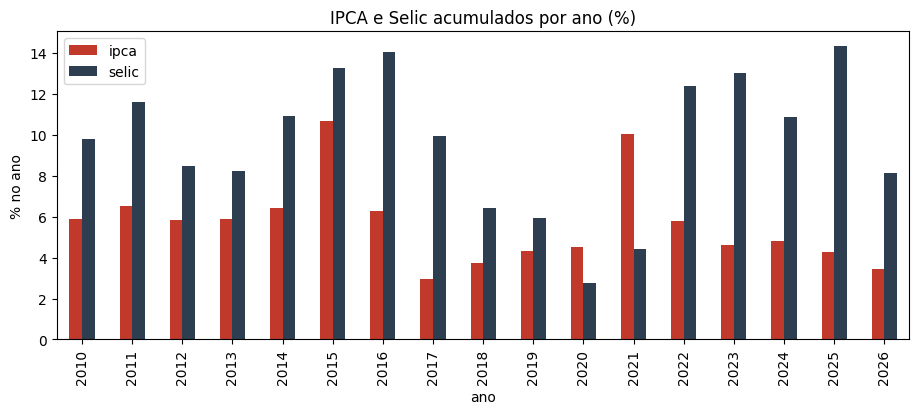

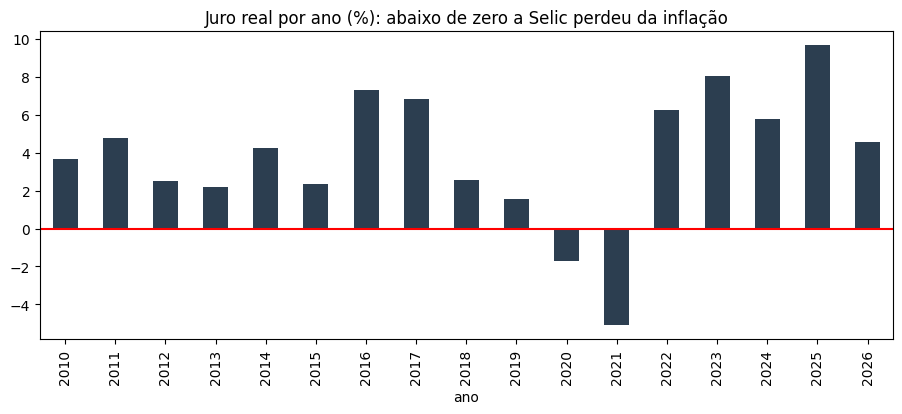

In [ ]:
anual[["ipca", "selic"]].plot(kind="bar", figsize=(11, 4), color=["#c0392b", "#2c3e50"])
plt.title("IPCA e Selic acumulados por ano (%)")
plt.ylabel("% no ano")
plt.show()

anual["juro_real"].plot(kind="bar", figsize=(11, 4), color="#2c3e50")
plt.axhline(0, color="red")
plt.title("Juro real por ano (%): abaixo de zero a Selic perdeu da inflação")
plt.show()

## 5. Manipulação de arquivos
Salvo a tabela anual em CSV e um resumo em texto, e depois leio o resumo de volta.

In [ ]:
anual.round(2).to_csv("resultados_anuais.csv")

with open("resumo.txt", "w", encoding="utf-8") as arquivo:      # escrever
    arquivo.write(f"Anos com juro real negativo: {analise.anos_juro_negativo()}\n")
    arquivo.write(f"Melhor ano: {analise.melhor_ano()}\n")
    arquivo.write(f"Pior ano: {analise.pior_ano()}\n")
    arquivo.write(f"Correlação IPCA x Selic: {analise.correlacao():.2f}\n")

with open("resumo.txt", "r", encoding="utf-8") as arquivo:      # ler de volta
    print(arquivo.read())

Anos com juro real negativo: [2020, 2021]
Melhor ano: 2025
Pior ano: 2021
Correlação IPCA x Selic: 0.07



## 6. Conclusões

- **Juro real negativo:** em 2020 e 2021 a Selic rendeu menos que a inflação. Em 2021 o IPCA acumulou cerca de 10% e a Selic só 4,4%, o pior ano da série (juro real de aproximadamente -5%).
- **Melhor período:** em 2025 a Selic ficou muito acima da inflação (juro real de aproximadamente 9,7%).
- **Selic reage à inflação, mas com atraso:** depois da alta do IPCA em 2021, a Selic subiu forte em 2022 e 2023. A correlação entre IPCA e Selic no mesmo ano é de apenas 0,07 (quase nenhuma). Isso combina com a ideia de que a Selic reage depois, e não no mesmo ano.
- **Limitação:** correlação não prova que um causa o outro. A Selic também depende de câmbio, expectativas e atividade econômica, que não estão nestes dados. O ano atual está incompleto e por isso ficou fora dos rankings.
